# Part 5 checks: does `submission/forecast.py` do what we claim?

Each section states a **claim**, how it could **fail**, and then the evidence. Nothing here tunes anything: the model, features and hyper-parameters are Sanath's (`cache/features_C.py`, `cache/probmodels_C.py`).

| # | Claim | What would failing look like |
|---|---|---|
| 1 | `forecast.py` is the same model as Sanath's validation model | validation predictions differ from `preds/sanath_laplace_mean.parquet` |
| 2 | No leakage: only readings at or before `issue_time` matter | output changes when later rows (or rows outside the look-back) are altered; **a control test must change the output** or the test is meaningless |
| 3 | The single-time features equal the training-time features | parity with `features_C.extract_features` breaks, especially in early January where windows are clipped |
| 4 | The look-back length (`TAIL = 200` h) is not a hidden degree of freedom | output depends on `TAIL` once it is at least the longest window |
| 5 | A model fitted up to a cutoff beats persistence on the next month | the proxy for the December test loses to persistence |
| 6 | The training rows we use (all 333 days, including January) are the right ones | dropping rows improves validation |
| 7 | It runs in time and passes the official check | `starter/check_submission.py` reports problems |

**How to run.** From the repo root (or from `part5/`), with `submission/` containing `forecast.py`, `model.json` and `bihar_stations.csv`. The notebook refits the model on two other cutoffs with `part5/fit_final_model.py` into a temporary folder; it never overwrites `submission/`. Takes a few minutes.

In [1]:
import os, sys, json, time, shutil, subprocess, importlib.util, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "baseline.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import baseline as B
from cache import features_C as FC, probmodels_C as PM

SUB = ROOT / "submission"
assert all((SUB / f).exists() for f in ("forecast.py", "model.json", "bihar_stations.csv")), "submission/ is incomplete"
W, stations = B.load_data()
ctx = FC.build_ctx(W, stations)
TMP = Path(tempfile.mkdtemp(prefix="p5_"))
RESULTS = {}                                              # check name -> bool, summarised at the end
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
mae = lambda a, b: float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

def load_forecast(folder, name):
    spec = importlib.util.spec_from_file_location(name, Path(folder) / "forecast.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod

def make_submission(train_end, tag):
    """Copy the submission folder and refit model.json with targets up to train_end (same script, same hyper-parameters)."""
    d = TMP / tag; d.mkdir()
    for f in ("forecast.py", "bihar_stations.csv"):
        shutil.copy(SUB / f, d / f)
    subprocess.run([sys.executable, str(ROOT / "part5" / "fit_final_model.py"), "--train-end", train_end, "--out", str(d / "model.json")],
                   check=True, capture_output=True)
    return d

sub_val = make_submission("2024-08-31 12:00", "val")      # validation protocol: targets <= 31 Aug
sub_oct = make_submission("2024-10-31 12:00", "oct")      # targets <= 31 Oct (stand-in for 'fit through 30 Nov, test December')
fc_val, fc_oct, fc_final = load_forecast(sub_val, "fc_val"), load_forecast(sub_oct, "fc_oct"), load_forecast(SUB, "fc_final")
final = json.load(open(SUB / "model.json"))
print("final model:", {k: final[k] for k in ("trained_through_target", "n_train_rows", "n_issue_days", "smearing", "l2")})

final model: {'trained_through_target': '2024-11-30 12:00', 'n_train_rows': 155844, 'n_issue_days': 333, 'smearing': 1.1118622833298306, 'l2': 0.001}


## Check 1: it is Sanath's model

**Claim.** `forecast.py` re-implements the features for one issue time and applies saved weights. If that is faithful, a model fitted with the *validation* protocol (targets up to 31 Aug) and called through `forecast()` on the 91 validation issue times must reproduce Sanath's saved predictions and his scores (28.16 / 15.74).

**Fail.** Any feature mistake (a wrong lag, `ddof`, clipping rule) would show up as a difference from his file. A tolerance of 1e-6 is far above floating-point noise and far below any real error.

In [2]:
_, T_val = B.issue_times()
t0 = time.perf_counter()
P = np.array([fc_val.forecast(W.loc[:t], t).to_numpy() for t in T_val])         # one call per validation issue day, history cut at t
dt = time.perf_counter() - t0
Y = W.loc[T_val + pd.Timedelta(hours=24)].to_numpy()
ref = pd.read_parquet("preds/sanath_laplace_mean.parquet").to_numpy()
diff = np.abs(P - ref).max()
ev = B.evaluate(P.ravel(), Y.ravel(), T_val)
print(f"through forecast():  RMSE {ev['RMSE']:.3f}  MAE {ev['MAE']:.3f}  | Sep {ev['RMSE Sep']:.2f}  Oct {ev['RMSE Oct']:.2f}  Nov {ev['RMSE Nov']:.2f}")
print(f"max |forecast() - Sanath's saved predictions| = {diff:.2e}   ({1000 * dt / len(T_val):.0f} ms per call)")
RESULTS["1  reproduces Sanath's saved validation predictions (<1e-6)"] = bool(diff < 1e-6)

through forecast():  RMSE 28.162  MAE 15.743  | Sep 20.05  Oct 17.57  Nov 41.05
max |forecast() - Sanath's saved predictions| = 9.58e-10   (36 ms per call)


## Check 2: no leakage, and the test has teeth

**Claim.** `forecast()` may only use rows of `history` at or before `issue_time`. Five perturbations of the input, one issue time (12 Nov 12:00):

| perturbation | expected |
|---|---|
| all rows **after** the issue time replaced by random numbers (the full frame is passed) | output unchanged |
| rows older than 250 h replaced by 999 | unchanged (outside the look-back) |
| columns shuffled | unchanged (output is re-indexed to station order) |
| full history passed, later rows present | unchanged |
| **control:** the last 6 hours *inside* the window replaced by random numbers | output **must change** |

The control matters: a test that cannot fail proves nothing. If the control did not change the output, the other four rows would be meaningless. (Differences of order 1e-13 appear because numpy sums in a different order on differently laid-out frames; the tolerance is 1e-9.)

In [3]:
t = pd.Timestamp("2024-11-12 12:00"); hist = W.loc[:t]
base = fc_final.forecast(hist, t).to_numpy(); rng = np.random.default_rng(0); h = pd.Timedelta(hours=1)

W_fut = W.copy(); m = W_fut.index > t;      W_fut.loc[m] = rng.uniform(0, 500, (int(m.sum()), 468))
W_old = hist.copy(); m = W_old.index < t - 250 * h; W_old.loc[m] = 999.0
W_ctl = hist.copy(); m = W_ctl.index > t - 6 * h;   W_ctl.loc[m] = rng.uniform(0, 500, (int(m.sum()), 468))
out = {"future rows scrambled (full frame passed)": fc_final.forecast(W_fut, t),
       "rows older than 250 h scrambled": fc_final.forecast(W_old, t),
       "columns shuffled": fc_final.forecast(hist.sample(frac=1, axis=1, random_state=0), t),
       "later rows present, same issue_time": fc_final.forecast(W, t),
       "CONTROL: last 6 h inside the window scrambled": fc_final.forecast(W_ctl, t)}
rows = []
for name, o in out.items():
    assert list(o.index) == list(stations.index), "output must be indexed by sensor_id in station order"
    d = float(np.abs(o.to_numpy() - base).max()); control = name.startswith("CONTROL")
    ok = (d > 1.0) if control else (d < 1e-9)
    rows.append(dict(perturbation=name, max_abs_diff=d, expected="changes" if control else "unchanged", passed=ok))
    RESULTS[f"2  {name}"] = bool(ok)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}"))

                                 perturbation  max_abs_diff  expected  passed
    future rows scrambled (full frame passed)      1.99e-13 unchanged    True
              rows older than 250 h scrambled      1.99e-13 unchanged    True
                             columns shuffled      0.00e+00 unchanged    True
          later rows present, same issue_time      0.00e+00 unchanged    True
CONTROL: last 6 h inside the window scrambled      1.50e+02   changes    True


## Check 3: the features equal the training-time features

**Why this exists.** `forecast.py` does **not** import `baseline.py` or `features_C.py`. The grader only sees our submission folder, so the file has to be self-contained; the alternative would be to ship copies of those modules and their imports. We chose a standalone file because it is short enough to read and explain, but that means correctness is something we must *prove*, not assume. This check does that by running both code paths on the same issue times and comparing the final predictions.

**Fail.** Differences above ~1e-9. The sample includes issue days 2-8 Jan, where the 7-day mean is clipped at the start of the data and the 24-hour windows are short: that is where a wrong clipping rule would show. (2 Jan 12:00 has only 37 hours of history; `forecast()` needs 25.)

In [4]:
T_all, _ = B.issue_times(24, train_end="2024-10-31 12:00")                      # 303 issue days, 2 Jan ... 30 Oct
y_all = B.targets(W, T_all)
X_all, names, _ = FC.extract_features(W, T_all, ctx, FC.FINAL_GROUPS)             # training-side features (batch)
mj = json.load(open(sub_val / "model.json")); mean, scale, coef = (np.asarray(mj[k]) for k in ("x_mean", "x_scale", "coef"))
rng = np.random.default_rng(1)
idx = sorted(set(rng.choice(len(T_all), 25, replace=False).tolist()) | {0, 1, 5, 6, 7, 8})
worst = 0.0
for j in idx:
    t = T_all[j]
    ref = np.clip(np.exp(coef[0] + ((X_all[j * 468:(j + 1) * 468] - mean) / scale) @ coef[1:]) * mj["smearing"] - 1, 0, 500)
    worst = max(worst, float(np.abs(fc_val.forecast(W.loc[:t], t).to_numpy() - ref).max()))
print(f"{len(idx)} issue times (incl. 2 Jan and 5-8 Jan with clipped windows): max |forecast() - batch features + weights| = {worst:.2e} ug/m3")
RESULTS["3  parity with features_C at 30 sampled issue times (<1e-9)"] = bool(worst < 1e-9)

30 issue times (incl. 2 Jan and 5-8 Jan with clipped windows): max |forecast() - batch features + weights| = 6.78e-12 ug/m3


## Check 4: where does `TAIL = 200` come from?

It is **not given** by the assignment; it is our choice. `forecast()` keeps only the last `TAIL` hours of `history` (a speed and clarity measure: the model never needs the earlier rows). The right value is *derived* from the features: the longest look-back is the 7-day station mean (168 h); everything else is shorter (trend windows reach back 48 h, lags 24 h). So the minimum is 168 and 200 is a safety margin.

**Test.** Compare the output for several `TAIL` values to the output with the *whole* history. Expected: identical once `TAIL >= 168`, different below (the 7-day mean is then clipped). If outputs depended on `TAIL` above 168, the file would contain a hidden tuning knob.

In [5]:
times = pd.to_datetime(["2024-03-15 12:00", "2024-07-04 12:00", "2024-09-20 12:00", "2024-11-12 12:00", "2024-11-29 12:00"])
def with_tail(k):
    fc_final.TAIL = k
    return np.array([fc_final.forecast(W.loc[:t], t).to_numpy() for t in times])
full = with_tail(10 ** 6)                                                          # whole history
rows = [dict(TAIL=k, max_abs_diff_vs_full_history=float(np.abs(with_tail(k) - full).max())) for k in (24, 48, 100, 167, 168, 200, 500)]
fc_final.TAIL = 200                                                                # restore
tail_tab = pd.DataFrame(rows); print(tail_tab.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
RESULTS["4  output independent of TAIL for TAIL >= 168"] = bool((tail_tab[tail_tab.TAIL >= 168].max_abs_diff_vs_full_history < 1e-9).all())
RESULTS["4  and TAIL < 168 does change it (so 168 is the true minimum)"] = bool(tail_tab[tail_tab.TAIL == 167].max_abs_diff_vs_full_history.item() > 1e-6)

 TAIL  max_abs_diff_vs_full_history
   24                      2.41e+02
   48                      2.96e+01
  100                      1.43e+01
  167                      3.35e-01
  168                      0.00e+00
  200                      0.00e+00
  500                      0.00e+00


## Check 5: an out-of-sample proxy for the December test

The December test refits on all targets up to 30 Nov and is scored on the 30 forecasts issued 30 Nov to 29 Dec. We cannot see December, but we can mimic the protocol one month earlier: **fit on targets up to 31 Oct, then call `forecast()` for the 30 issue times 31 Oct 12:00 to 29 Nov 12:00** (targets 1 to 30 Nov), the same 30 calls `check_submission.py` makes. This is genuinely out of sample, and it covers the hardest month (November, the rising season).

**Limits.** It is one month; December may behave differently (and its pollution level is likely higher, which favours the log model if anything, but that is an expectation, not a result). It also uses the same data we have looked at for model selection.

**Win criterion for the 5 "beat persistence" points:** RMSE below persistence over all 30 forecasts.

                                                    RMSE    MAE
fitted through 31 Oct (proxy for the final model)  41.21  28.67
fitted through 31 Aug (validation model)           41.05  28.56
persistence                                        47.81  31.70

model beats persistence on 23 of 30 days (daily RMSE over the 468 stations)


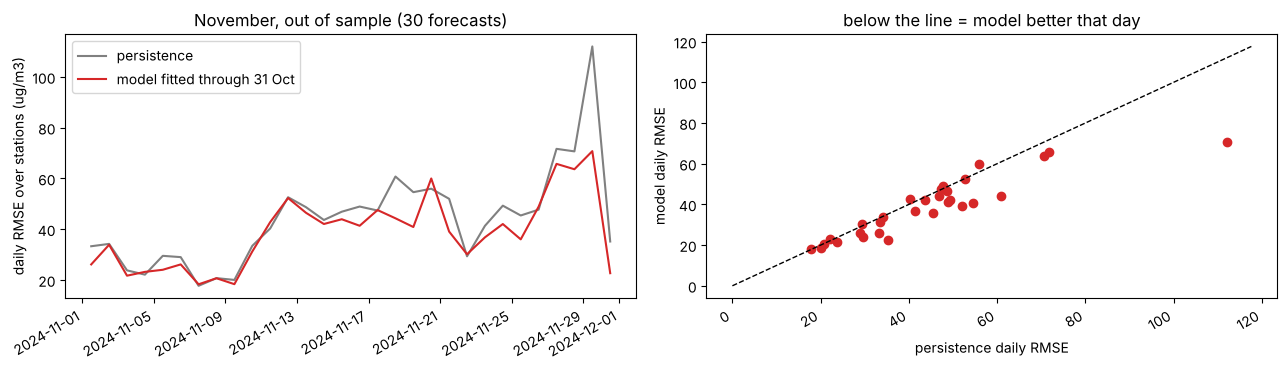

In [6]:
TT = pd.date_range("2024-10-31 12:00", "2024-11-29 12:00", freq="D")
Pn = np.array([fc_oct.forecast(W.loc[:t], t).to_numpy() for t in TT])
Pv = np.array([fc_val.forecast(W.loc[:t], t).to_numpy() for t in TT])
Yn = W.loc[TT + pd.Timedelta(hours=24)].to_numpy(); Qn = W.loc[TT].to_numpy()            # truth, persistence
tab = pd.DataFrame({"RMSE": [rmse(Pn, Yn), rmse(Pv, Yn), rmse(Qn, Yn)], "MAE": [mae(Pn, Yn), mae(Pv, Yn), mae(Qn, Yn)]},
                   index=["fitted through 31 Oct (proxy for the final model)", "fitted through 31 Aug (validation model)", "persistence"]).round(2)
print(tab.to_string())
d_m, d_p = np.sqrt(((Pn - Yn) ** 2).mean(1)), np.sqrt(((Qn - Yn) ** 2).mean(1))
print(f"\nmodel beats persistence on {(d_m < d_p).sum()} of {len(TT)} days (daily RMSE over the 468 stations)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(TT + pd.Timedelta(hours=24), d_p, label="persistence", c="gray"); ax[0].plot(TT + pd.Timedelta(hours=24), d_m, label="model fitted through 31 Oct", c="C3")
ax[0].set_ylabel("daily RMSE over stations (ug/m3)"); ax[0].set_title("November, out of sample (30 forecasts)"); ax[0].legend(); fig.autofmt_xdate()
ax[1].scatter(d_p, d_m, c="C3"); lim = [0, max(d_p.max(), d_m.max()) * 1.05]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlabel("persistence daily RMSE"); ax[1].set_ylabel("model daily RMSE"); ax[1].set_title("below the line = model better that day")
plt.tight_layout(); plt.savefig("part5_nov_proxy.png", dpi=150); plt.show()
RESULTS["5  proxy: RMSE below persistence on the 30 November forecasts"] = bool(rmse(Pn, Yn) < rmse(Qn, Yn))

## Check 6: which training rows?

The final refit uses **all** 333 issue days (155,844 rows), including early January, whose 7-day window is clipped at the start of the data. Two different questions are easy to confuse:

* **(a) Drop only the rows whose features are clipped?** For this model that is issue days 2-7 Jan (6 days, 2,808 rows), because the longest window is 7 days.
* **(b) Drop January (or January and February) altogether?** January averages 168 ug/m3 at noon against 15-37 from March to September. Only January and February look like November (104) and probably December.

Each variant is evaluated twice: with the *validation protocol* (fit through 31 Aug, score Sep-Nov) and with the *proxy protocol* (fit through 31 Oct, score the 30 November forecasts). Same model, same hyper-parameters; only the set of rows changes.

                                  variant  rows_val_fit  val_RMSE  val_MAE  val_Nov  rows_proxy_fit  nov_proxy_RMSE  nov_proxy_MAE
                                 all rows        113256     28.16    15.74    41.05          141804           41.21          28.67
drop clipped 7-day window (issue < 8 Jan)        110448     28.17    15.75    41.07          138996           41.42          28.82
                     drop January targets         99684     29.63    16.34    44.22          128232           44.80          31.14
                   drop Jan + Feb targets         86112     33.22    18.13    51.36          114660           48.81          34.14
persistence: validation RMSE 32.75, November-proxy RMSE 47.81


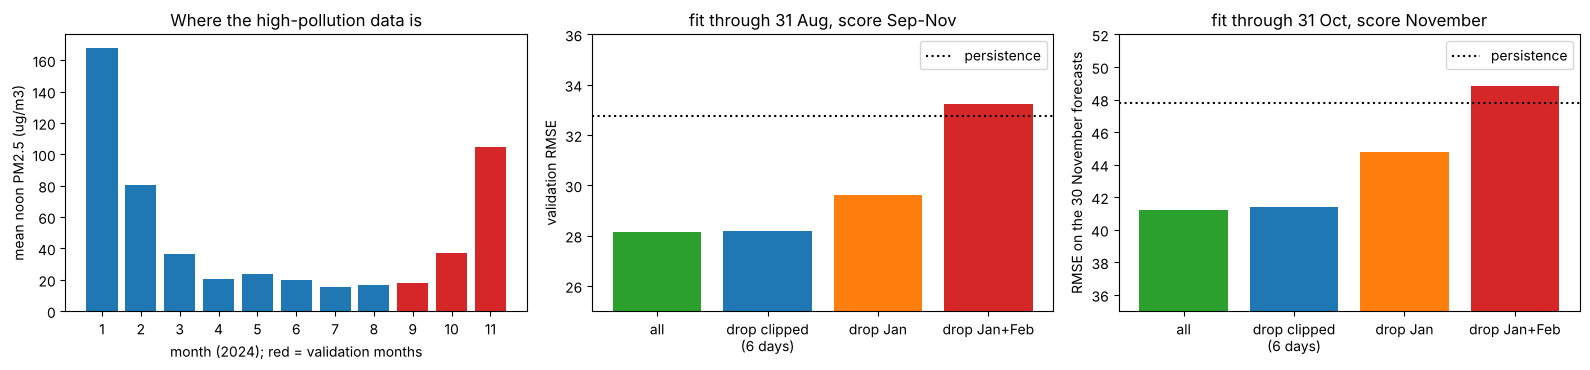

In [7]:
tdate = pd.DatetimeIndex(T_all + pd.Timedelta(hours=24))                           # target dates of the training issue days
Xv, _, _ = FC.extract_features(W, T_val, ctx, FC.FINAL_GROUPS); yv = B.targets(W, T_val)
Xn, _, _ = FC.extract_features(W, TT, ctx, FC.FINAL_GROUPS);    yn = Yn.ravel(); pers_n = Qn.ravel()
variants = {"all rows": lambda T, td: np.ones(len(T), bool),
            "drop clipped 7-day window (issue < 8 Jan)": lambda T, td: T >= pd.Timestamp("2024-01-08 12:00"),
            "drop January targets": lambda T, td: td.month != 1,
            "drop Jan + Feb targets": lambda T, td: td.month > 2}
rows = []
for name, keep in variants.items():
    k = np.repeat(keep(T_all, tdate), 468)
    k_val = k & np.repeat(tdate <= pd.Timestamp("2024-08-31 12:00"), 468)              # validation protocol: targets <= 31 Aug
    m1 = PM.LogLaplaceForecaster().fit(X_all[k_val], y_all[k_val]); e = B.evaluate(m1.predict(Xv), yv, T_val)
    m2 = PM.LogLaplaceForecaster().fit(X_all[k], y_all[k]);          p = np.clip(m2.predict(Xn), 0, None)
    rows.append(dict(variant=name, rows_val_fit=int(k_val.sum()), val_RMSE=e["RMSE"], val_MAE=e["MAE"], val_Nov=e["RMSE Nov"],
                     rows_proxy_fit=int(k.sum()), nov_proxy_RMSE=rmse(p, yn), nov_proxy_MAE=mae(p, yn)))
rows_tab = pd.DataFrame(rows); print(rows_tab.round(2).to_string(index=False)); print("persistence: validation RMSE 32.75, November-proxy RMSE %.2f" % rmse(pers_n, yn))

mon = W[W.index.hour == 12].groupby(W[W.index.hour == 12].index.month).mean().mean(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(mon.index, mon.values, color=["C0"] * 8 + ["C3"] * 3); ax[0].set_xticks(mon.index); ax[0].set_xlabel("month (2024); red = validation months")
ax[0].set_ylabel("mean noon PM2.5 (ug/m3)"); ax[0].set_title("Where the high-pollution data is")
short = ["all", "drop clipped\n(6 days)", "drop Jan", "drop Jan+Feb"]
ax[1].bar(short, rows_tab.val_RMSE, color=["C2", "C0", "C1", "C3"]); ax[1].axhline(32.75, c="k", ls=":", label="persistence"); ax[1].set_ylim(25, 36); ax[1].legend()
ax[1].set_ylabel("validation RMSE"); ax[1].set_title("fit through 31 Aug, score Sep-Nov")
ax[2].bar(short, rows_tab.nov_proxy_RMSE, color=["C2", "C0", "C1", "C3"]); ax[2].axhline(rmse(pers_n, yn), c="k", ls=":", label="persistence"); ax[2].set_ylim(35, 52); ax[2].legend()
ax[2].set_ylabel("RMSE on the 30 November forecasts"); ax[2].set_title("fit through 31 Oct, score November")
plt.tight_layout(); plt.savefig("part5_row_choice.png", dpi=150); plt.show()
base_v = rows_tab.val_RMSE[0]
RESULTS["6  dropping the 6 clipped-window days changes validation RMSE by < 0.05"] = bool(abs(rows_tab.val_RMSE[1] - base_v) < 0.05)
RESULTS["6  dropping January makes validation RMSE worse by > 1"] = bool(rows_tab.val_RMSE[2] - base_v > 1.0)

**Reading (numbers from the table above).**

* Dropping the six rows with a clipped 7-day window changes nothing (28.16 to 28.17 validation, 41.21 to 41.42 on the November proxy). So the clipping is **not** a problem for this model, and there is no reason to throw those rows away.
* Dropping **January's targets** is clearly worse: validation RMSE 28.16 to 29.63 (November 41.05 to 44.22), November proxy 41.21 to 44.80. Dropping January and February is much worse again (33.22, which is worse than persistence at 32.75; 48.81 on the proxy).
* The monthly means show why: January (168) and February (80) are the only training months with pollution comparable to November (104). A model trained without them has never seen smoggy conditions, and the model's error is dominated by exactly those conditions.

For the report: *"We use all 333 issue days (155,844 rows: 468 stations, targets 3 Jan to 30 Nov). Removing January from the training data raised validation RMSE from 28.16 to 29.63, because January is the only winter-smog regime in the training period."* The earlier statement that dropping rows "with clipped windows" hurt referred to a different model with a 30-day window, which removed all of January; the January effect, not the window clipping, is the cause.

## Check 7: timing and the official grader script

The grader calls `forecast()` 30 times with a 10-second limit per call and checks the output format (a `pd.Series` indexed by the 468 sensor ids, all finite). `check_submission.py` does the same on November; its November scores are **in-sample** for the final model (November is in its training data), so they are not a test score.

In [8]:
ts = []
for t in TT:
    t0 = time.perf_counter(); o = fc_final.forecast(W.loc[:t].copy(), t); ts.append(time.perf_counter() - t0)
print(f"30 calls, final model: median {1000 * np.median(ts):.0f} ms, max {1000 * max(ts):.0f} ms (limit 10 000 ms)")
print(f"output: {type(o).__name__}, {len(o)} stations, all finite: {bool(np.isfinite(o).all())}, range {o.min():.1f} to {o.max():.1f}")
r = subprocess.run([sys.executable, "starter/check_submission.py", str(SUB)], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-900:]); print(r.stderr[-500:] if r.returncode else "")
RESULTS["7  max call time below 10 s"] = bool(max(ts) < 10)
RESULTS["7  check_submission.py reports OK"] = "RESULT: OK" in r.stdout

30 calls, final model: median 29 ms, max 33 ms (limit 10 000 ms)
output: Series, 468 stations, all finite: True, range 4.7 to 138.7


Running /tmp/claude-0/-home-claude/92e8b249-77e5-539c-a6ae-e9a81079d74e/scratchpad/repo_copy/submission/forecast.py on 30 November issue times ...

Call time: median 0.02 s, max 0.04 s

November sanity check over 30 forecasts (NOT a test score):
  your forecast  RMSE  40.80  MAE  28.35
  persistence    RMSE  47.81  MAE  31.70

RESULT: OK - format and timing look right.




## Summary

In [9]:
summary = pd.DataFrame({"check": list(RESULTS), "passed": list(RESULTS.values())})
print(summary.to_string(index=False)); print("\nALL PASSED" if summary.passed.all() else "\nSOMETHING FAILED")
shutil.rmtree(TMP, ignore_errors=True)
for f in (ROOT / "submission").glob("__pycache__"): shutil.rmtree(f, ignore_errors=True)   # do not zip caches

                                                                  check  passed
            1  reproduces Sanath's saved validation predictions (<1e-6)    True
                           2  future rows scrambled (full frame passed)    True
                                     2  rows older than 250 h scrambled    True
                                                    2  columns shuffled    True
                                 2  later rows present, same issue_time    True
                       2  CONTROL: last 6 h inside the window scrambled    True
            3  parity with features_C at 30 sampled issue times (<1e-9)    True
                          4  output independent of TAIL for TAIL >= 168    True
          4  and TAIL < 168 does change it (so 168 is the true minimum)    True
          5  proxy: RMSE below persistence on the 30 November forecasts    True
6  dropping the 6 clipped-window days changes validation RMSE by < 0.05    True
                 6  dropping January mak